# Exercise 5: Choosing an Architecture for the Data

# Prerequisites
Same setup as before: NumPy, matplotlib and scikit-learn are all you need. The data are small toy examples generated in the notebook, so nothing to download.

This time the question is: **which model fits which data?** Single-cell, spatial and metagenomic data all end up as tables of numbers, but what decides the model is the **structure around the table**: is one sample an image, a node with neighbours, a list of tokens or just a vector?

**Total: 12 points.** Questions are part of the points, answer them in 1–3 sentences in the markdown cells.

In [15]:
# These are the libraries that we used - feel free to use others if you want
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

np.random.seed(0)

# 1)
From data to architecture. (4 points)

In Lectures 2–4 you met several kinds of models: linear and logistic regression, MLPs, autoencoders, CNNs, graph neural networks (GNNs) and transformers. Each of them expects a certain **kind of input** and has a built-in assumption about the data: a CNN assumes that neighbouring pixels belong together, a GNN that connected nodes influence each other, a transformer that the input is a sequence of tokens. Lecture 5 showed one example of each on biomedical data.

## a) Which model for which data? (3 points, 0.75 per scenario)
For each scenario, fill in the table:

- **Input shape:** what **one** example looks like when it enters the model, e.g. "a vector of 20 numbers", "a 64×64 grey image", "a graph with … nodes, each with … features".
- **Architecture:** the kind of model you would use (name it freely, you may combine models).
- **Reason:** one sentence: which property of the data makes this architecture a good fit?

There is not only one correct answer: a different choice is accepted if the reason fits the data.

| # | Data and task |
|---|---|
| 1 | H&E-stained tissue sections of 23 breast cancer patients. For ~30,000 spots you have **both** the 224×224 pixel image patch of the spot and the measured expression of 250 genes. You want to predict the expression of these genes **from new H&E images alone**. |
| 2 | One spatial transcriptomics slide of a brain section: 4,000 spots, each with the expression of 18,000 genes **and its (x, y) position**. There are no labels. You want to divide the tissue into regions (spatial domains). |
| 3 | Gut metagenomes of 300 people (150 with colorectal cancer, 150 healthy): the relative abundances of 1,000 bacterial species per person. You want to predict cancer vs healthy. |
| 4 | 30 million single-cell profiles (cells × 20,000 genes) collected from many public atlases, **mostly without labels**. You want **one** model that can later be adapted to several tasks (e.g. cell-type annotation, predicting the response to a drug) with little labelled data. |

| # | Input shape | Architecture | Reason |
|---|---|---|---|
| 1 | One RGB image patch of 224 × 224 × 3 pixels | CNN | At prediction time only the image is available. Neighbouring pixels form local tissue patterns (nuclei, glands), and a CNN is built to use exactly this kind of structure. It is a regression task, and the data should be split by patient, not by spot. |
| 2 | One graph with 4,000 nodes | GNN graph autoencoder | Spots that lie next to each other usually belong to the same tissue region. A GNN combines information from neighbouring spots, and since there are no labels, the autoencoder learns the representation on its own. |
| 3 | A vector of 1,000 numbers | Logistic regression with L1/L2 regularisation | There are only 300 samples but 1,000 features, and the features have no spatial or sequential order like pixels do. A simple regularised model overfits less than a deep network and is easier to interpret. |
| 4 | A sequence of gene tokens | Transformer foundation model | The dataset is huge and mostly unlabelled, and transformers scale well to that. Self-attention can capture interactions between genes, and a pretrained model can be adapted to new tasks with little labelled data (transfer learning). |

## b) Question (1 point)
A logistic regression model trained on gut microbiome species reaches an **AUC of 0.95** in 5-fold cross-validation within one study, but only **0.62** when it is tested on a study from another country. Give **two** possible reasons, and say how the model should be evaluated.

*Your answer:* The studies may use different DNA extraction, sequencing protocols or bioinformatics pipelines. The model then learns signals that only go with cancer in the training study. Furthermore, diet, geography, ethnicity, age or medication change the baseline microbiome. These confounders can relate to cancer differently in each country, so the patterns the model learned no longer hold.

# 2)
One cell, three representations. (3 points)

The same measurement can be given to a model in different forms, and the form decides which architecture can use it. Below is a toy single-cell matrix: 6 cells × 8 marker genes, **already normalized and log-transformed**. The markers are typical for blood cells: CD3E, IL7R (T cells), MS4A1, CD79A (B cells), LYZ, CD14 (monocytes), NKG7, GNLY (NK cells).

1. **A vector of 8 numbers per cell:** this is the matrix row itself, the input of an MLP or a logistic regression. Nothing to do.
2. **A sentence of gene tokens:** the input of a transformer foundation model (task a).
3. **A node in a graph:** the input of a GNN or of graph clustering such as Leiden (task b).

In [16]:
genes = ["CD3E", "IL7R", "MS4A1", "CD79A", "LYZ", "CD14", "NKG7", "GNLY"]
cells = ["cell_1", "cell_2", "cell_3", "cell_4", "cell_5", "cell_6"]

X_cells = np.array([
    # CD3E IL7R MS4A1 CD79A  LYZ  CD14  NKG7  GNLY
    [2.8,  2.1,  0.0,  0.0,  0.3,  0.0,  0.6,  0.0],   # cell_1
    [2.5,  1.6,  0.0,  0.2,  0.0,  0.0,  0.0,  0.0],   # cell_2
    [0.0,  0.0,  2.9,  2.2,  0.4,  0.0,  0.0,  0.0],   # cell_3
    [0.1,  0.0,  2.4,  2.6,  0.0,  0.0,  0.0,  0.0],   # cell_4
    [0.0,  0.0,  0.0,  0.0,  3.1,  2.3,  0.0,  0.0],   # cell_5
    [0.9,  0.0,  0.0,  0.0,  0.0,  0.0,  2.2,  2.7],   # cell_6
])
print(X_cells.shape)

(6, 8)


## a) A cell as a sentence of genes (1 point)
Geneformer and Nicheformer turn a cell into a sentence by **rank encoding**: drop the genes with expression 0, then sort the remaining genes from highest to lowest expression. The gene names are the tokens, as the words were in Exercise 4.

Write `rank_tokens(cell, genes)` that returns this list of gene names for one row of `X_cells`, and print the sentence of every cell. Then check that `rank_tokens(2 * X_cells[0], genes)` gives the same sentence as `rank_tokens(X_cells[0], genes)`.

In [17]:
def rank_tokens(cell, genes):
    # Your code
    nz = np.where(cell > 0)[0] # indices of genes with expression > 0
    order = nz[np.argsort(-cell[nz], kind="stable")] # sort them from highest to lowest
    tokens = [genes[i] for i in order] # indices -> gene names
    return tokens

# Print the sentence of every cell
for name, cell in zip(cells, X_cells):
    print(name, rank_tokens(cell, genes))

# Same sentence if all values are doubled?
print(rank_tokens(2 * X_cells[0], genes) == rank_tokens(X_cells[0], genes))

cell_1 ['CD3E', 'IL7R', 'NKG7', 'LYZ']
cell_2 ['CD3E', 'IL7R', 'CD79A']
cell_3 ['MS4A1', 'CD79A', 'LYZ']
cell_4 ['CD79A', 'MS4A1', 'CD3E']
cell_5 ['LYZ', 'CD14']
cell_6 ['GNLY', 'NKG7', 'CD3E']
True


## b) Cells as nodes of a kNN graph (1 point)
For clustering, single-cell tools connect each cell to its **k nearest neighbours** in expression space.

Compute the Euclidean distance between every pair of cells and build the 6×6 **adjacency matrix** `A_knn` with `A_knn[i, j] = 1` if cell j is one of the **k = 2** nearest neighbours of cell i (a cell is not its own neighbour), else 0. Print `A_knn` and the two neighbours of every cell. Is `A_knn` symmetric?

In [18]:
def knn_adjacency(X, k):
    # Your code
    n = X.shape[0]
    # Pairwise Euclidean distances
    D = np.sqrt(((X[:, None, :] - X[None, :, :]) ** 2).sum(axis=2))
    np.fill_diagonal(D, np.inf) # a cell is not its own neighbour
    A = np.zeros((n, n), dtype=int)
    for i in range(n):
        A[i, np.argsort(D[i])[:k]] = 1 # the k closest cells of cell i
    return A

A_knn = knn_adjacency(X_cells, k=2)
# Print A_knn and the neighbours of every cell
print(A_knn)
for i, name in enumerate(cells):
    print(name, "->", [cells[j] for j in np.where(A_knn[i])[0]])
print("Symmetric:", np.array_equal(A_knn, A_knn.T))

[[0 1 0 0 0 1]
 [1 0 0 0 0 1]
 [0 1 0 1 0 0]
 [0 1 1 0 0 0]
 [1 1 0 0 0 0]
 [1 1 0 0 0 0]]
cell_1 -> ['cell_2', 'cell_6']
cell_2 -> ['cell_1', 'cell_6']
cell_3 -> ['cell_2', 'cell_4']
cell_4 -> ['cell_2', 'cell_3']
cell_5 -> ['cell_1', 'cell_2']
cell_6 -> ['cell_1', 'cell_2']
Symmetric: False


## c) Question (1 point)
For each of the three representations (vector of 8 numbers, sentence of gene tokens, node in the kNN graph), name **one** piece of information it keeps and **one** it loses. Use your results from a) and b).

*Your answer:* The vector keeps the exact expression values but loses any context about other cells. The gene sentence keeps which genes are expressed and their order, so it is robust to scaling (a), but it loses the magnitudes and drops all zero genes. The kNN graph keeps which cells are similar to each other, but it loses the actual expression values and distances, and for rare cell types it can force misleading edges (cell_5 in b).

# 3)
Why neighbours help: the idea of a graph neural network. (5 points)

In spatial transcriptomics each spot has an expression profile **and** a position. Few molecules are captured per spot, so the expression of a single spot is noisy. But neighbouring spots usually belong to the same tissue region. A GNN uses this: each layer replaces the features of a node by an average over its neighbours:

$$X_{\text{smooth}} = \hat{A}\,X$$

Here $X$ has one row per spot, and $\hat{A}$ is the **row-normalized adjacency matrix** of the spatial neighbour graph: $\hat{A}_{ij} = 1/\text{(number of neighbours of } i\text{, counting } i \text{ itself)}$ if $j$ is a neighbour of $i$ or $j = i$, else 0. A real GCN layer also multiplies by a learned weight matrix, $\hat{A} X W$; here we look only at the averaging step and use logistic regression as the classifier.

**Toy tissue:** the cell below generates a 30×30 grid of spots with three horizontal layers, like the layers of the brain cortex: an upper layer (rows 0–12), a **thin middle layer** (rows 13–15) and a deep layer (rows 16–29). Each spot has 20 genes; genes 0, 1 and 2 are markers of layers 0, 1 and 2 (slightly higher there), the other 17 genes are noise. Spot `i` is at row `i // 30` and column `i % 30`. In this toy example we know the layer of every spot, so we can measure how well it is predicted.

X: (900, 20)  y: (900,)  spots per layer: [390  90 420]


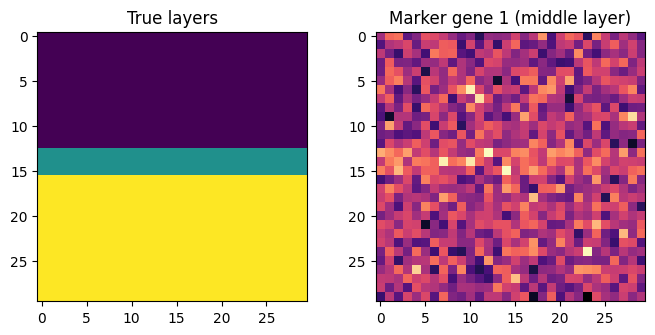

In [19]:
def make_toy_tissue(n=30, n_genes=20, shift=1.0, seed=0):
    rng = np.random.default_rng(seed)
    rows = np.repeat(np.arange(n), n)              # row of every spot
    cols = np.tile(np.arange(n), n)                # column of every spot
    layer = np.digitize(rows, [13, 16])            # 0: rows 0-12, 1: rows 13-15, 2: rows 16-29
    X = rng.normal(1.0, 1.0, (n * n, n_genes))     # noisy expression
    for l in range(3):
        X[layer == l, l] += shift                  # marker gene l is higher in layer l
    coords = np.stack([rows, cols], axis=1)
    return X, layer, coords

X, y, coords = make_toy_tissue()
print("X:", X.shape, " y:", y.shape, " spots per layer:", np.bincount(y))

fig, ax = plt.subplots(1, 2, figsize=(8, 3.5))
ax[0].imshow(y.reshape(30, 30), cmap="viridis"); ax[0].set_title("True layers")
ax[1].imshow(X[:, 1].reshape(30, 30), cmap="magma"); ax[1].set_title("Marker gene 1 (middle layer)")
plt.show()

## a) The spatial neighbour graph (1.5 points)
Build the 900×900 adjacency matrix of the grid: spot `i` is connected to the spots directly **above, below, left and right** of it (if they exist) and to **itself** (self-loop). Then row-normalize it, so that every row sums to 1: this is `A_hat`.

Check your matrix: print the number of neighbours (including the spot itself) of a corner spot (0), a spot on the edge (5) and an inner spot (35), and check that all rows of `A_hat` sum to 1.

In [20]:
def grid_adjacency(n):
    # Your code
    return A_hat

A_hat = grid_adjacency(30)
# Checks

NameError: name 'A_hat' is not defined

## b) Averaging over the neighbours (1 point)
Compute `X_smooth = A_hat @ X`. Plot marker gene 1 as a 30×30 image **before** and **after** smoothing, side by side.

In [ ]:
# Smoothing and plot

## c) Predicting the layer with and without neighbours (1.5 points)
Split the spots into training and test spots:

```python
idx_train, idx_test = train_test_split(np.arange(900), test_size=0.3, stratify=y, random_state=0)
```

Train a `LogisticRegression(max_iter=1000)` that predicts the layer of a spot (1) from its own expression `X` and (2) from the smoothed expression `X_smooth`. Report the **test accuracy** of both. Then predict the layer of **all** 900 spots with both models and plot the true layers and the two predicted maps side by side.

In [ ]:
# Train, evaluate and plot

## d) More averaging steps, and a question (1 point)
A GNN with several layers averages several times. Repeat the smoothing `s` times ($\hat{A}^s X$) for `s` = 1, 3, 10, 30, 100 and 300, and print for each `s` the test accuracy and the **recall of the thin middle layer** (fraction of its test spots predicted as layer 1).

Then answer: why does averaging over neighbours help, why does it get worse when it is repeated too often, and how is "close" in this graph different from "close" in the kNN graph of Part 2?

In [ ]:
# Repeated smoothing

*Your answer:*